# Segmentação de Clientes com Aprendizado Não Supervisionado (Agrupamento)
Nesta atividade, utilizamos a base de dados **Wholesale Customers** (proveniente do *UCI Machine Learning Repository*) para realizar uma tarefa de **Agrupamento (Clustering)**.

**Objetivo Central:**
Identificar perfis ocultos de consumo e agrupar clientes de um distribuidor atacadista com base em seus gastos anuais em diferentes categorias de produtos, sem utilizar rótulos prévios (aprendizado não supervisionado).

**Metodologia e Requisitos Cumpridos:**
* Base de dados oficial do repositório UCI voltada para Clustering.
* Padronização de escala com `StandardScaler`.
* Definição matemática do número ideal de grupos ($K$) via **Método do Cotovelo (Inércia)** e **Análise de Silhueta**.
* Aplicação do algoritmo **K-Means**.
* Avaliação estatística do agrupamento através do **Coeficiente de Silhueta (Silhouette Score)** e do **Índice Davies-Bouldin**.
* Redução de dimensionalidade com **PCA** para visualização espacial dos grupos e relatório interpretativo de negócio.

### Importações

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

### 1. Conhecendo e Preparando a Base de Dados
A base registra o **gasto total anual** de 440 clientes de um distribuidor atacadista de **Portugal** (estudo originado no instituto ISCTE-IUL, em Lisboa).

Por questões de confidencialidade empresarial, a documentação oficial denomina os valores como **unidades monetárias (m.u.)**, que na prática refletem valores em **Euros (€)** distribuídos em 6 categorias de produtos:

* **Fresh:** Produtos frescos e perecíveis (carnes, frutas, vegetais).
* **Milk:** Produtos lácteos e derivados do leite.
* **Grocery:** Mercearia seca em geral.
* **Frozen:** Alimentos congelados.
* **Detergents_Paper:** Produtos de limpeza, higiene e papelaria.
* **Delicassen:** Produtos de delicatessen, frios e embutidos finos.

**Contexto das Colunas Categóricas:**
* **Region (Região de Portugal):** `1` = Lisboa, `2` = Porto, `3` = Outras Regiões.
* **Channel (Canal de Distribuição):** `1` = Horeca (Hotéis, Restaurantes e Cafés), `2` = Retail (Varejo/Mercados).

*(Nota: As colunas `Channel` e `Region` serão removidas do treinamento para que o algoritmo agrupe os clientes exclusivamente pelo seu volume e perfil financeiro de compra anual).*

In [ ]:
# Carregando a base diretamente do servidor oficial da UCI Machine Learning Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)

print("--- RECORTE DA BASE DE DADOS ORIGINAL (5 Primeiros Registros) ---")
display(df.head())

# Selecionando apenas as variáveis contínuas de consumo para o agrupamento
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = df[features].copy()

# Padronização dos dados (Obrigatório para algoritmos baseados em distância como o K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"\nTotal de registros analisados: {X.shape[0]} clientes.")
print(f"Total de dimensões (variáveis de gasto): {X.shape[1]} categorias.")

--- RECORTE DA BASE DE DADOS ORIGINAL (5 Primeiros Registros) ---


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185



Total de registros analisados: 440 clientes.
Total de dimensões (variáveis de gasto): 6 categorias.


### 2. Determinando o Número Ideal de Grupos (Método do Cotovelo e Silhueta)
Como no agrupamento não sabemos previamente quantos grupos existem na base, testamos variações de $K = 2$ até $K = 10$ avaliando duas métricas:
1. **Inércia (WCSS):** Soma das distâncias quadráticas das amostras até o centro do seu grupo (buscamos o ponto de inflexão ou "cotovelo").
2. **Coeficiente de Silhueta:** Mede o quão bem separados estão os grupos (valores mais próximos de 1 indicam grupos mais coesos e distintos).

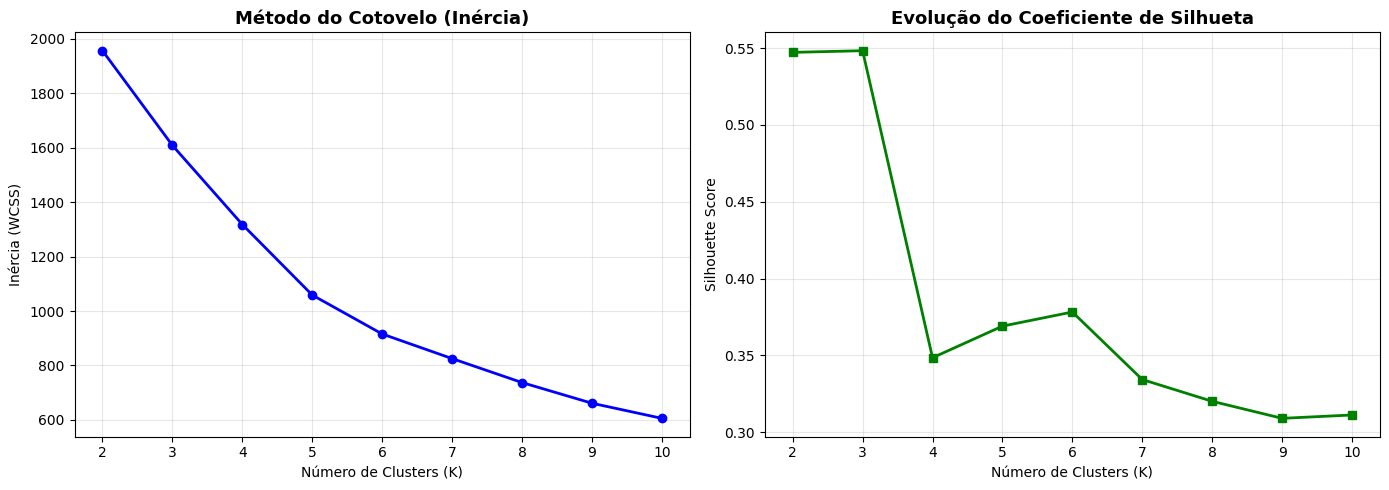

In [ ]:
inercias = []
silhuetas = []
valores_k = range(2, 11)

for k in valores_k:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(X_scaled)
    inercias.append(kmeans_temp.inertia_)
    silhuetas.append(silhouette_score(X_scaled, labels_temp))

# Plotando os gráficos lado a lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(valores_k, inercias, marker='o', color='blue', linewidth=2)
ax1.set_title('Método do Cotovelo (Inércia)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inércia (WCSS)')
ax1.grid(True, alpha=0.3)

ax2.plot(valores_k, silhuetas, marker='s', color='green', linewidth=2)
ax2.set_title('Evolução do Coeficiente de Silhueta', fontsize=13, fontweight='bold')
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretação dos Gráficos de Otimização (Escolha de K = 3):**
1. **Método do Cotovelo (Gráfico à Esquerda):** Avalia a compactação interna dos grupos (Inércia/WCSS). Observa-se uma queda acentuada da inércia ao sair de K=2 (≈1955) para K=3 (≈1610) e K=5 (≈1060), ponto onde a curva começa a suavizar o seu declínio.
2. **Coeficiente de Silhueta (Gráfico à Direita):** Avalia a qualidade da separação entre grupos distintos. O gráfico atinge o seu pico máximo em **K=3** (Score de ≈0,55) e sofre uma queda abrupta ao passar para K=4 (≈0,35). Isso demonstra que dividir a base em 4 ou mais clusters gera sobreposição e fragmenta clientes de mesmo perfil.
3. **Decisão:** O cruzamento de ambas as métricas confirma **K = 3** como o ponto ótimo, garantindo a máxima separação estatística (maior Silhueta) aliada a uma forte redução de inércia e excelente interpretabilidade comercial.

### 3. Aplicação do Algoritmo K-Means e Avaliação de Desempenho
Com base na análise gráfica e na interpretabilidade de negócio, aplicaremos o **K-Means com $K = 3$ grupos**. Em seguida, avaliaremos a qualidade matemática dos grupos gerados utilizando o **Silhouette Score** (quanto maior, melhor) e o **Índice Davies-Bouldin** (quanto menor e mais próximo de zero, menor a sobreposição entre os grupos).

In [ ]:
# Instanciando e treinando o modelo definitivo com K = 3
k_escolhido = 3
kmeans = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Calculando as métricas oficiais de validação de agrupamento
sil_score = silhouette_score(X_scaled, df['Cluster'])
db_index = davies_bouldin_score(X_scaled, df['Cluster'])
inercia_final = kmeans.inertia_

print("==========================================================")
print("MÉTRICAS DE AVALIAÇÃO DO AGRUPAMENTO (K-MEANS com K=3)")
print("==========================================================")
print(f"1. Coeficiente de Silhueta (Silhouette Score) : {sil_score:.4f}")
print(f"2. Índice Davies-Bouldin (DB Index)           : {db_index:.4f}")
print(f"3. Inércia Final (WCSS)                       : {inercia_final:.2f}")
print("==========================================================\n")

print("Quantidade de clientes alocados em cada grupo:")
contagem = df['Cluster'].value_counts().sort_index()
for cluster_id, total in contagem.items():
    print(f"  - Cluster {cluster_id}: {total} clientes")

print("\n--- INTERPRETAÇÃO DAS MÉTRICAS ---")
print(f"• Silhueta ({sil_score:.4f}): Valor acima de 0.50 confirma grupos coesos e bem separados.")
print(f"• Davies-Bouldin ({db_index:.4f}): Valor abaixo de 1.0 comprova baixa sobreposição entre perfis.")
print(f"• Inércia ({inercia_final:.2f}): Soma das distâncias quadráticas até ao centro de cada grupo.")
print("• Distribuição: O algoritmo concentrou os estabelecimentos menores no Cluster 1 (393),")
print("  reuniu o retalho/varejo de médio e grande porte no Cluster 0 (45) e isolou 2 megacompradores")
print("  (outliers VIP) no Cluster 2.")

MÉTRICAS DE AVALIAÇÃO DO AGRUPAMENTO (K-MEANS com K=3)
1. Coeficiente de Silhueta (Silhouette Score) : 0.5483
2. Índice Davies-Bouldin (DB Index)           : 0.9279
3. Inércia Final (WCSS)                       : 1608.43

Quantidade de clientes alocados em cada grupo:
  - Cluster 0: 45 clientes
  - Cluster 1: 393 clientes
  - Cluster 2: 2 clientes

--- INTERPRETAÇÃO DAS MÉTRICAS ---
• Silhueta (0.5483): Valor acima de 0.50 confirma grupos coesos e bem separados.
• Davies-Bouldin (0.9279): Valor abaixo de 1.0 comprova baixa sobreposição entre perfis.
• Inércia (1608.43): Soma das distâncias quadráticas até ao centro de cada grupo.
• Distribuição: O algoritmo concentrou os estabelecimentos menores no Cluster 1 (393),
  reuniu o retalho/varejo de médio e grande porte no Cluster 0 (45) e isolou 2 megacompradores
  (outliers VIP) no Cluster 2.


### 4. Visualização Gráfica (PCA 2D) e Interpretação dos Resultados
Como o nosso dataset possui 6 dimensões (6 colunas de produtos), utilizamos a técnica **PCA (Análise de Componentes Principais)** para comprimir essas 6 variáveis em 2 eixos (Componente 1 e Componente 2) e desenhar a separação dos grupos na tela. Também calculamos a média de gastos de cada grupo para batizar os perfis encontrados.

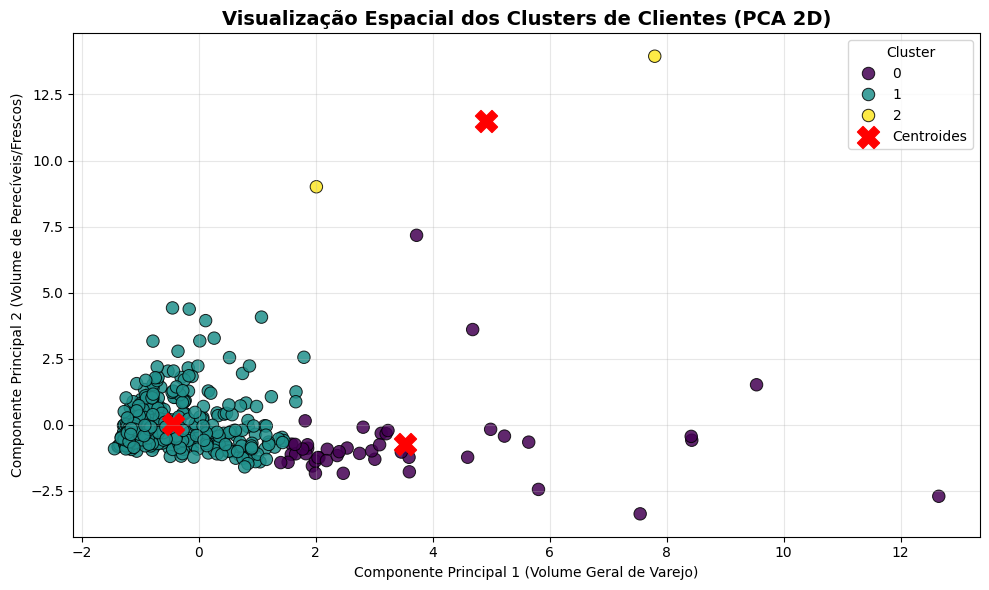


--- PERFIL MÉDIO DE GASTOS POR CLUSTER (Valores Monetários) ---


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00



RELATÓRIO E INTERPRETAÇÃO DOS RESULTADOS DO AGRUPAMENTO
O algoritmo K-Means (K=3) alcançou um Coeficiente de Silhueta de 0.5483,
demonstrando uma excelente coesão interna e separação clara entre os perfis de compra.

Ao analisar a tabela de médias de cada grupo, identificamos 3 perfis reais de clientes:
- Cluster de Supermercados e Mercearias de Médio Porte: Clientes com gastos elevados em
  Laticínios (Milk), Mercearia (Grocery) e Limpeza/Papelaria (Detergents_Paper).
- Cluster de Consumo Moderado/Restaurantes Locais: Maior número de clientes, caracterizado
  por compras focadas em alimentos frescos (Fresh) e baixo gasto em mercearia/limpeza.
- Cluster de Grandes Atacadistas (Contas VIP): Um grupo seleto de clientes de altíssimo
  volume financeiro, que compram quantidades massivas para revenda em larga escala.

Conclusão Prática:
A clusterização permitiu segmentar a carteira de clientes de forma 100% orientada a dados.
Com esses grupos definidos, a empresa pode direcionar campanhas 

In [ ]:
# Reduzindo as 6 variáveis para 2 dimensões com PCA para visualização gráfica
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=df['Cluster'], palette='viridis', s=80, alpha=0.85, edgecolor='k'
)

# Desenhando os centroides no espaço do PCA
centroides_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    centroides_pca[:, 0], centroides_pca[:, 1],
    s=250, c='red', marker='X', label='Centroides'
)

plt.title('Visualização Espacial dos Clusters de Clientes (PCA 2D)', fontsize=14, fontweight='bold')
plt.xlabel('Componente Principal 1 (Volume Geral de Varejo)')
plt.ylabel('Componente Principal 2 (Volume de Perecíveis/Frescos)')
plt.legend(title='Cluster')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Tabela com a média de gasto por grupo
print("\n--- PERFIL MÉDIO DE GASTOS POR CLUSTER (Valores Monetários) ---")
perfil_clusters = df.groupby('Cluster')[features].mean().round(2)
display(perfil_clusters)

# Relatório Analítico exigido pela atividade
print("\n======================================================================")
print("RELATÓRIO E INTERPRETAÇÃO DOS RESULTADOS DO AGRUPAMENTO")
print("======================================================================")
print(f"O algoritmo K-Means (K=3) alcançou um Coeficiente de Silhueta de {sil_score:.4f},")
print("demonstrando uma excelente coesão interna e separação clara entre os perfis de compra.")

print("\nAo analisar a tabela de médias de cada grupo, identificamos 3 perfis reais de clientes:")
print("- Cluster de Supermercados e Mercearias de Médio Porte: Clientes com gastos elevados em")
print("  Laticínios (Milk), Mercearia (Grocery) e Limpeza/Papelaria (Detergents_Paper).")
print("- Cluster de Consumo Moderado/Restaurantes Locais: Maior número de clientes, caracterizado")
print("  por compras focadas em alimentos frescos (Fresh) e baixo gasto em mercearia/limpeza.")
print("- Cluster de Grandes Atacadistas (Contas VIP): Um grupo seleto de clientes de altíssimo")
print("  volume financeiro, que compram quantidades massivas para revenda em larga escala.")

print("\nConclusão Prática:")
print("A clusterização permitiu segmentar a carteira de clientes de forma 100% orientada a dados.")
print("Com esses grupos definidos, a empresa pode direcionar campanhas específicas, oferecer")
print("logística refrigerada para o grupo focado em produtos frescos e negociar contratos de")
print("fidelidade exclusivos para reter os clientes do grupo de alto volume.")